In [103]:
import numpy as np
import sys, os
import matplotlib.pyplot as plt
from scipy.constants import lambda2nu, nu2lambda, c
from scipy.optimize import curve_fit
from scipy.interpolate import PchipInterpolator, CubicSpline
lumapiFile = "C:\\Program Files\\Lumerical\\v261\\api\\python\\lumapi.py"

import importlib.util
import sys

spec = importlib.util.spec_from_file_location("lumapi", lumapiFile)
lumapi = importlib.util.module_from_spec(spec)
sys.modules["lumapi"] = lumapi
spec.loader.exec_module(lumapi)

import lumapi

In [104]:
from IPython.core.display import HTML
from IPython.display import display, Math
from IPython.core.pylabtools import figsize

HTML("""
<style>
.output_png {
    display: table-cell;
    text-align: center;
    vertical-align: middle;
}
</style>
""")

figsize(8, 4)

In [105]:
# Unidades

## Comprimento
um = 1e-6
nm = 1e-9

## Frequência

GHz = 1e9
THz = 1e12

## Tempo

ns = 1e-9
ps = 1e-12

# Constantes

pi = np.pi
lambda_ = 1550*nm
f_ = c/lambda_

## Parametros do guia de onda

w = 500*nm
h = 220*nm

neff = 2.4455
ng = 4.4909
alpha_dB = 3 # dB/cm

# Mapas de cores

cmap1 = plt.cm.viridis
cmap2 = plt.cm.plasma
cmap3 = plt.cm.inferno
cmap4 = plt.cm.magma
cmap5 = plt.cm.coolwarm
cmap6 = plt.cm.turbo
cmap7 = plt.cm.GnBu
cmap8 = plt.cm.winter

# Anel com FSR de $100\,GHz$ #

Projeto de um anel add-drop alinhado à grade ITU-T de $100\,GHz$ na banda C. Parâmetros:

1) $FSR=100\,GHz$ ($\approx 0,80\,nm$);
2) $FWHM=5\,GHz$;
3) Ressonância em $193,1\,THz$ ($1552,52\,nm$, $Q= 38260$);
4) Guia de $500\times 220\,nm$ ($n_{eff}=2,4455$, $n_g=4,1909$, $\alpha_{dB}=3\,dB/cm$);
5) Acopladores simétricos.

Das especificações extraimos: 

1 - Comprimento:

$$L=\frac{c}{n_g {FSR}_f}\approx 715,3\,\mu m\,,$$

Ajuste fino:

$$L=\frac{m\lambda_0}{n_{eff}}\rightarrow m=1126$$
$$L=\frac{m\lambda_0}{n_{eff}}=714,84\,\mu m\,;$$

2 - Atenuação do guia:

$$a=10^{-\alpha_{dB}L/20}\approx0,9756\,;$$

3 - Finesse, autoacoplamento e acoplamento cruzado:

$$\mathcal{F}=\frac{FSR}{FWHM}=20\,;$$

$$x=\left(\frac{-\pi+\sqrt{\pi^2+4\mathcal{F}^2}}{2\mathcal{F}}\right)^2\approx 0,8548\,;$$

acopladores simétricos: $r_1=r_2=r$ e

$$r=\sqrt{\frac{x}{a}}\approx 0,9360\rightarrow\kappa^2\approx 0,1239\,;$$

4 - Desempenho:

$$T_d(\phi=0)=\frac{(1-r^2)^2a}{(1-r^2a)^2}\approx 0,7095\,,$$
$$T_p(\phi=0)=\frac{r^2(1-a)^2}{(1-r^2a)^2}\approx 0,0247\,,$$

em $dB$:

$$T_d(\phi=0)\approx -1,49\,dB\,,$$
$$T_p(\phi=0)\approx -16,07\,dB\,.$$

## Desempenho dos acopladores direcionais ##

In [106]:
intcApi = lumapi.INTERCONNECT()

dlambda = 100*nm

lambda_1 = lambda_ - dlambda/2
lambda_2 = lambda_ + dlambda/2

df = c*dlambda/(lambda_1*lambda_2)

N_ONA = 5001

In [107]:
intcApi.deleteall()
intcApi.addelement("ebeam_dc_te1550")
intcApi.set('name', 'acoplador')
intcApi.set('x position', 0)
intcApi.set('y position', 0)

intcApi.addelement('Optical Network Analyzer')
intcApi.set('name', 'ONA')
intcApi.set('x position', -40)
intcApi.set('y position', -200)
intcApi.set('number of input ports', 2)
intcApi.set('number of points', N_ONA)
intcApi.set('center frequency', f_)
intcApi.set('frequency range', df)

intcApi.connect('ONA', 'output', 'acoplador', 'opt_1')
intcApi.connect('acoplador', 'opt_3', 'ONA', 'input 1')
intcApi.connect('acoplador', 'opt_4', 'ONA', 'input 2')

1.0

In [108]:
dLc = 2.5*um
Lc_array = np.arange(0, 50*um, dLc)

H_1550_array = []
for Lc in Lc_array:
    intcApi.switchtodesign()
    intcApi.setnamed('acoplador', 'coupling_length', Lc)
    intcApi.run()

    H = intcApi.getresult('ONA', 'input 2/mode 1/gain')['TE gain (dB)']
    H_1550 = H[int((N_ONA-1)/2)]
    H_1550_array.append(H_1550)

H_1550_array = np.array(H_1550_array)

intcApi.close()

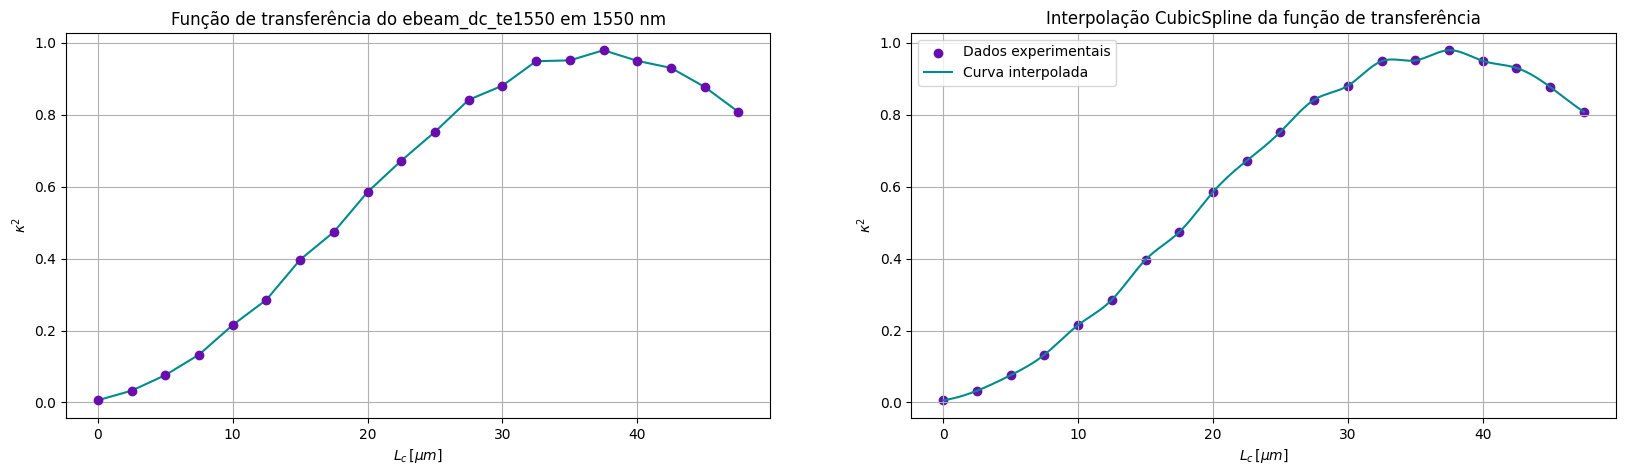

In [231]:
fig, ax = plt.subplots(1,2, figsize = (20,5))

ax[0].plot(Lc_array/um, 10**(H_1550_array/10), color = 'darkcyan', marker = 'o', markerfacecolor='#6A0DAD', markeredgecolor='#6A0DAD')
ax[0].grid(True)
ax[0].set_title('Função de transferência do ebeam_dc_te1550 em 1550 nm')
ax[0].set_xlabel(r'$L_c\,[\mu m]$')
ax[0].set_ylabel(r'$\kappa^2$')

acoplamento = CubicSpline(Lc_array, 10**(H_1550_array/10))

Lc_array_2 = np.linspace(0, np.max(Lc_array), 1001)
ax[1].scatter(Lc_array/um, 10**(H_1550_array/10), color = '#6A0DAD', label = 'Dados experimentais')
ax[1].plot(Lc_array_2/um, acoplamento(Lc_array_2), color = 'darkcyan', markerfacecolor='#6A0DAD', markeredgecolor='#6A0DAD', label = 'Curva interpolada')
ax[1].grid(True)
ax[1].set_title('Interpolação CubicSpline da função de transferência')
ax[1].set_xlabel(r'$L_c\,[\mu m]$')
ax[1].set_ylabel(r'$\kappa^2$')
ax[1].legend(loc='best')

plt.show()

## Comprimento de acoplamento necessário para o projeto ##

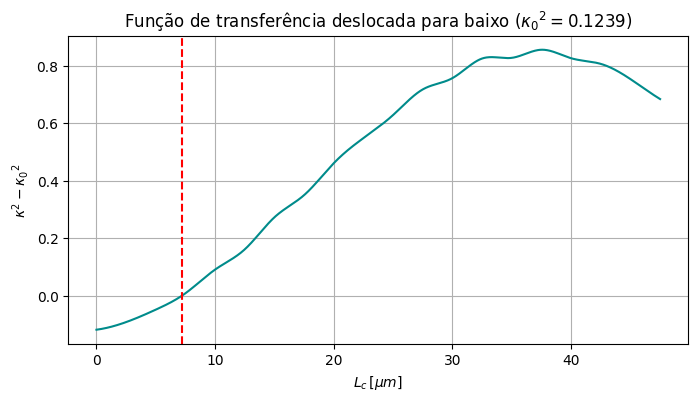

In [145]:
kappa2 = 0.1239

def f(Lc):
    return acoplamento(Lc) - kappa2

plt.plot(Lc_array_2/um, f(Lc_array_2), color = 'darkcyan', markerfacecolor='#6A0DAD', markeredgecolor='#6A0DAD')
plt.grid(True)
plt.axvline(7.18, linestyle = '--', color = 'red')
plt.title(r'Função de transferência deslocada para baixo (${\kappa_0}^2=%.4f$)' %kappa2)
plt.xlabel(r'$L_c\,[\mu m]$')
plt.ylabel(r'$\kappa^2-{\kappa_0}^2$')
plt.show()

In [232]:
Lc_0 = 0
Lc_1 = 10*um

N = 101

for i in range(N):
    Lc_m = (Lc_0 + Lc_1)/2

    if f(Lc_m)*f(Lc_1) > 0:
        Lc_1 = Lc_m
    else:
        Lc_0 = Lc_m

Lc = (Lc_0 + Lc_1)/2

print('O comprimento de acoplamento para um acoplamento de \u03BA² = %.4f é Lc = %.2f \u03BCm' %(kappa2, Lc/um))

O comprimento de acoplamento para um acoplamento de κ² = 0.1239 é Lc = 7.18 μm


## Geometria do guia curvo do projeto ##

In [223]:
L = 714.915*um # Com ajustes finos
gap = 200*nm
R = (L - 2*Lc)/(2*pi)

print('gap = %d nm, R = %.2f um, Lc = %.2f \u03BCm' %(gap/nm, R/um, Lc/um))

gap = 200 nm, R = 111.50 um, Lc = 7.18 μm


# Função de transferência do anel projetado #

### Equações do anel add-drop ###

In [224]:
def phi(lambda_, L, n_g=ng):
    num = 2*pi*n_g*L
    den = lambda_
    return num/den

def T_p(phi,r1,r2,a):
    num = r1**2 - 2*r1*r2*a*np.cos(phi) + (r2*a)**2
    den = 1 - 2*r1*r2*a*np.cos(phi) + (r1*r2*a)**2
    return num/den

def T_d(phi,r1,r2,a):
    num = (1 - r1**2)*(1 - r2**2)*a
    den = 1 - 2*r1*r2*a*np.cos(phi) + (r1*r2*a)**2
    return num/den

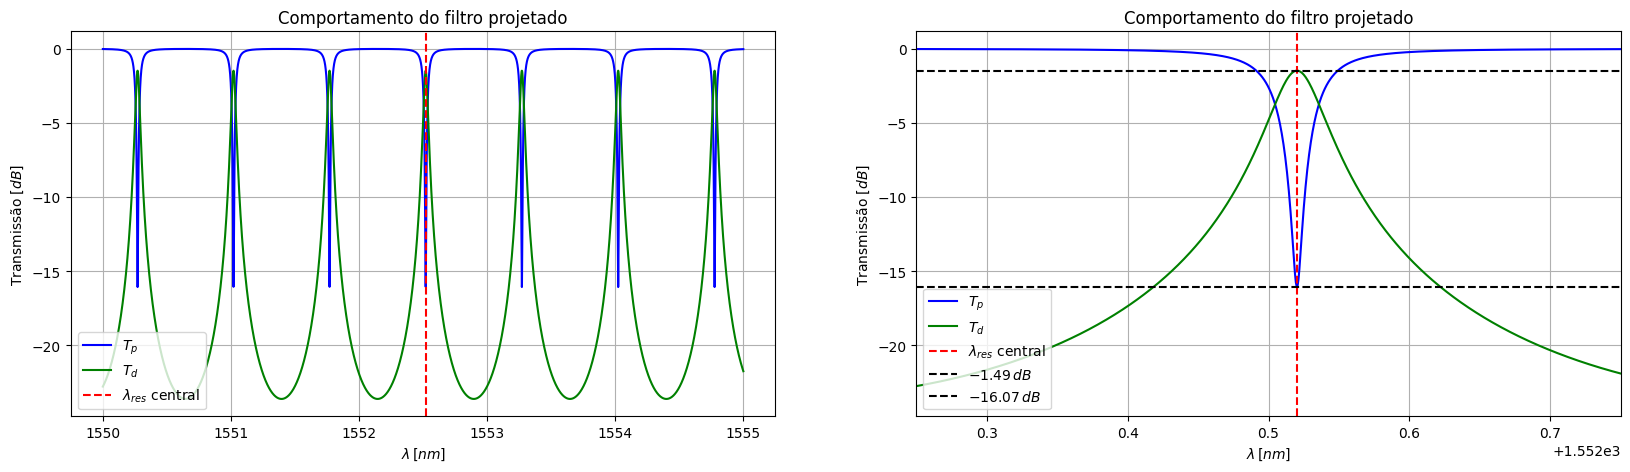

In [230]:
a = 0.9756
r = 0.9360

lambda_array = np.linspace(1550*nm, 1555*nm, 8001)

phi_array = phi(lambda_array, L, ng)
Tp_array = T_p(phi_array, r, r, a)
Td_array = T_d(phi_array, r, r, a)

Tp_dB_array = 10*np.log10(Tp_array)
Td_dB_array = 10*np.log10(Td_array)

fig, ax = plt.subplots(1,2, figsize = (20,5))

ax[0].plot(lambda_array/nm, Tp_dB_array, color = 'blue', label = '$T_p$')
ax[0].plot(lambda_array/nm, Td_dB_array, color = 'green', label = r'$T_d$')

ax[0].axvline(1552.52, linestyle = '--', color = 'red', label = r'$\lambda_{res}$ central')

ax[0].grid(True)
ax[0].set_xlabel(r'$\lambda\,[nm]$')
ax[0].set_ylabel(r'Transmissão [$dB$]')
ax[0].legend(loc = 'lower left')
ax[0].set_title('Comportamento do filtro projetado')

ax[1].plot(lambda_array/nm, Tp_dB_array, color = 'blue', label = '$T_p$')
ax[1].plot(lambda_array/nm, Td_dB_array, color = 'green', label = r'$T_d$')

ax[1].axvline(1552.52, linestyle = '--', color = 'red', label = r'$\lambda_{res}$ central')
ax[1].axhline(-1.49, linestyle = '--', color = 'black', label = r'$-1.49\,dB$')
ax[1].axhline(-16.07, linestyle = '--', color = 'black', label = r'$-16.07\,dB$')

ax[1].grid(True)
ax[1].set_xlabel(r'$\lambda\,[nm]$')
ax[1].set_ylabel(r'Transmissão [$dB$]')
ax[1].legend(loc = 'lower left')
ax[1].set_title('Comportamento do filtro projetado')
ax[1].set_xlim([1552.25, 1552.75])

plt.show()